# Taller 2 – Redes Neuronales Convolucionales, Transfer Learning y Data Augmentation

**Suficiencia – Introducción al Aprendizaje Profundo**
**Estudiante:** Diego Alexander Valencia Calderón
**Dataset:** Oxford-IIIT Pet (37 razas de perros y gatos)

**Objetivo:** clasificar la raza de una mascota con redes convolucionales y medir, con cuatro experimentos comparables, el efecto del *Transfer Learning*, del *fine-tuning* y del *Data Augmentation*. La meta es una exactitud (*accuracy*) mínima del 90 % en el conjunto de prueba con el mejor experimento.

> **Entorno recomendado:** Google Colab con GPU T4. En CPU el entrenamiento de los cuatro experimentos puede tardar varias horas.

| Sección | Contenido | Requisito |
|---|---|---|
| 1 | Preparación, análisis y procesamiento de los datos | a |
| 2 | Construcción de los modelos con EfficientNetB0 preentrenada | b |
| 3 | Funciones comunes de entrenamiento y evaluación | c |
| 4 | Experimento A: CNN desde cero (línea base) | c |
| 5 | Experimento B: Transfer Learning con backbone congelado | c |
| 6 | Experimento C: Transfer Learning + fine-tuning | c |
| 7 | Data Augmentation y Experimento D: fine-tuning + DA | c, d |
| 8 | Comparación de experimentos | e |
| 9 | Análisis técnico | f |
| 10 | Resumen de métricas y red de seguridad | — |

**Salidas generadas**

| Archivo | Contenido |
|---|---|
| `figuras/01_distribucion_clases.png` | Distribución de clases por conjunto |
| `figuras/02_ejemplos_dataset.png` | Ejemplos del dataset con su raza |
| `figuras/03_data_augmentation.png` | Efecto del Data Augmentation sobre una imagen |
| `figuras/04_curvas_entrenamiento.png` | Curvas de accuracy y loss de los 4 experimentos |
| `figuras/05_comparacion_experimentos.png` | Accuracy de prueba de los 4 experimentos |
| `figuras/06_matriz_confusion_mejor.png` | Matriz de confusión del mejor modelo |
| `modelos/t2_exp*.keras` | Mejor modelo de cada experimento |
| `resultados/history_exp*.csv` | Historial de entrenamiento de cada experimento |
| `resultados/tabla_comparativa.csv` | Tabla comparativa de los experimentos |
| `resultados/classification_report_mejor.txt` | Precision, recall y F1 por clase del mejor modelo |
| `resultados/metricas_taller2.json` | Resumen de métricas del taller |

## 0. Configuración del entorno

Detecta si el notebook corre en Colab o en local, define las rutas de salida, fija la semilla para reproducibilidad y verifica la GPU (indispensable en este taller).

In [44]:
import sys
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
NOTEBOOK = "taller2_cnn_tl_da/taller2_cnn_tl_da.ipynb"  # ruta de este notebook dentro del proyecto

if EN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Busca la carpeta del proyecto en "Mi unidad" (hasta 4 niveles), sin importar dónde se haya subido
    MI_UNIDAD = Path("/content/drive/MyDrive")
    REPO_DIR = next(
        (
            ruta.parents[1]
            for nivel in ("*", "*/*", "*/*/*", "*/*/*/*")
            for ruta in MI_UNIDAD.glob(f"{nivel}/{NOTEBOOK}")
        ),
        MI_UNIDAD / "Suficiencia_Aprendizaje_Profundo",
    )
else:
    # En local se sube desde el directorio actual hasta encontrar la carpeta que contiene este notebook
    REPO_DIR = next(
        (carpeta for carpeta in (Path.cwd(), *Path.cwd().parents) if (carpeta / NOTEBOOK).exists()),
        Path.cwd().parent,
    )

assert REPO_DIR.exists(), f"No se encontró la carpeta del proyecto en {REPO_DIR}"

TALLER_DIR = REPO_DIR / "taller2_cnn_tl_da"
FIG_DIR = TALLER_DIR / "figuras"
RES_DIR = TALLER_DIR / "resultados"
MOD_DIR = TALLER_DIR / "modelos"
for carpeta in (FIG_DIR, RES_DIR, MOD_DIR):
    carpeta.mkdir(parents=True, exist_ok=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from tensorflow import keras

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)  # fija las semillas de Python, NumPy y TensorFlow

print("Entorno:", "Google Colab" if EN_COLAB else "Local")
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no disponible")
print("Repositorio:", REPO_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Entorno: Google Colab
TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Repositorio: /content/drive/MyDrive/Introducción al aprendizaje profundo/Suficiencia_Aprendizaje_Profundo


## 1. Preparación, análisis y procesamiento de los datos (a)

### 1.1 Parámetros generales y red de seguridad

La variable `OBJETIVO` define la tarea:

- `"label"`: clasificación de las **37 razas** (tarea principal).
- `"species"`: clasificación binaria **perro / gato** (red de seguridad).

Si el mejor experimento no alcanza el 90 % en las 37 razas, basta con cambiar `OBJETIVO = "species"` en esta celda y ejecutar todo de nuevo. El número de clases, los nombres, la capa de salida y todas las figuras se ajustan solos. La partición train / val / test es la misma en ambos casos, porque se estratifica siempre por raza.

La celda también instala `importlib_resources` si falta: `tensorflow_datasets` lo necesita para descargar el dataset y algunas versiones de Colab no lo incluyen.

In [23]:
import importlib
import importlib.util
import subprocess

# tensorflow_datasets necesita el paquete importlib_resources al descargar el dataset,
# pero algunas imágenes de Colab (Python 3.13) no lo traen instalado: se instala solo si falta
if importlib.util.find_spec("importlib_resources") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "importlib_resources"], check=True)
    importlib.invalidate_caches()

from tensorflow.keras.applications import efficientnet

# Tarea de clasificación: "label" = 37 razas | "species" = perro/gato (red de seguridad)
OBJETIVO = "label"

TAM_IMAGEN = 224
FORMA_ENTRADA = (TAM_IMAGEN, TAM_IMAGEN, 3)
TAMANO_BATCH = 32
PROPORCION_VAL = 0.15
META_ACCURACY = 0.90
AUTOTUNE = tf.data.AUTOTUNE

print(f"Tarea: {OBJETIVO} | imágenes {TAM_IMAGEN}x{TAM_IMAGEN} | batch {TAMANO_BATCH}")

Tarea: label | imágenes 224x224 | batch 32


### 1.2 Carga del dataset

Oxford-IIIT Pet contiene fotografías de 37 razas (12 de gatos y 25 de perros). Cada ejemplo incluye la imagen, la raza (`label`), la especie (`species`), la máscara de segmentación y el recuadro de la cabeza. `tensorflow_datasets` lo descarga la primera vez (unos 800 MB) y lo entrega dividido en `train` (3.680 imágenes) y `test` (3.669).

Se usa `shuffle_files=False` para que el orden de lectura sea siempre el mismo, condición necesaria para que la partición de validación sea reproducible.

In [24]:
(ds_train_completo, ds_test_crudo), info = tfds.load(
    "oxford_iiit_pet",
    split=["train", "test"],
    with_info=True,
    shuffle_files=False,
)

NOMBRES_RAZAS = info.features["label"].names
NOMBRES_CLASES = info.features[OBJETIVO].names
NUM_CLASES = len(NOMBRES_CLASES)
ETIQUETAS_LEGIBLES = [nombre.replace("_", " ") for nombre in NOMBRES_CLASES]

print("Versión del dataset:", info.version)
print("Splits originales:", {nombre: split.num_examples for nombre, split in info.splits.items()})
print(f"Número de clases de la tarea: {NUM_CLASES}")
print(info.features)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-train.tfrecord-[0-…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_iiit_pet/incomplete.HBRPOI_4.0.0/oxford_iiit_pet-test.tfrecord-[0-9…

Dataset oxford_iiit_pet downloaded and prepared to /root/tensorflow_datasets/oxford_iiit_pet/4.0.0. Subsequent calls will reuse this data.
Versión del dataset: 4.0.0
Splits originales: {'train': 3680, 'test': 3669}
Número de clases de la tarea: 37
FeaturesDict({
    'file_name': Text(shape=(), dtype=string),
    'head_bbox': BBoxFeature(shape=(4,), dtype=float32),
    'image': Image(shape=(None, None, 3), dtype=uint8),
    'label': ClassLabel(shape=(), dtype=int64, num_classes=37),
    'segmentation_mask': Image(shape=(None, None, 1), dtype=uint8),
    'species': ClassLabel(shape=(), dtype=int64, num_classes=2),
})


### 1.3 Partición en entrenamiento, validación y prueba

| Conjunto | Origen | Proporción | Uso |
|---|---|---|---|
| Entrenamiento | Split `train` | 85 % | Ajustar los pesos |
| Validación | Split `train` | 15 % | *Early stopping*, selección del mejor modelo de cada experimento y elección del mejor experimento |
| Prueba | Split `test` completo | — | Evaluación final, sin intervenir en ninguna decisión |

Para estratificar se leen primero solo las etiquetas, sin decodificar las imágenes, lo que hace la lectura muy rápida. Luego `train_test_split` elige los índices con semilla 42 y estratificación por raza, y el dataset se filtra por posición.

In [25]:
from sklearn.model_selection import train_test_split

# Lectura rápida de etiquetas: se omite la decodificación de imágenes y máscaras
DECODIFICADORES = {"image": tfds.decode.SkipDecoding(), "segmentation_mask": tfds.decode.SkipDecoding()}


def leer_etiquetas(split):
    ds = tfds.load("oxford_iiit_pet", split=split, decoders=DECODIFICADORES, shuffle_files=False)
    return np.array([(int(ej["label"]), int(ej["species"])) for ej in tfds.as_numpy(ds)])


etiquetas_train_completo = leer_etiquetas("train")  # columnas: [raza, especie]
etiquetas_test = leer_etiquetas("test")
COLUMNA = 0 if OBJETIVO == "label" else 1

indices = np.arange(len(etiquetas_train_completo))
idx_train, idx_val = train_test_split(
    indices,
    test_size=PROPORCION_VAL,
    stratify=etiquetas_train_completo[:, 0],  # siempre por raza: también queda estratificado por especie
    random_state=SEMILLA,
)
mascara_train = tf.constant(np.isin(indices, idx_train))


def filtrar(ds, en_train):
    # Conserva los ejemplos cuya posición pertenece (o no) a la partición de entrenamiento
    return (
        ds.enumerate()
        .filter(lambda i, ejemplo: tf.equal(tf.gather(mascara_train, i), en_train))
        .map(lambda i, ejemplo: ejemplo)
    )


ds_train_crudo = filtrar(ds_train_completo, True)
ds_val_crudo = filtrar(ds_train_completo, False)

y_train_np = etiquetas_train_completo[np.sort(idx_train), COLUMNA]
y_val_np = etiquetas_train_completo[np.sort(idx_val), COLUMNA]
y_test_np = etiquetas_test[:, COLUMNA]

resumen = pd.DataFrame(
    {"Imágenes": [len(y_train_np), len(y_val_np), len(y_test_np)]},
    index=pd.Index(["Entrenamiento", "Validación", "Prueba"], name="Conjunto"),
)
resumen["Porcentaje (%)"] = (resumen["Imágenes"] / resumen["Imágenes"].sum() * 100).round(2)
display(resumen)

,Imágenes,Porcentaje (%)
Conjunto,,
Entrenamiento,3128,42.56
Validación,552,7.51
Prueba,3669,49.93


### 1.4 Análisis exploratorio (EDA)

**Distribución de clases.** Se revisa si las clases están balanceadas en los tres conjuntos.

,Entrenamiento,Validación,Prueba,Total
Clase,,,,
Bombay,82,14,88,184
staffordshire bull terrier,85,15,89,189
Egyptian Mau,79,14,97,190
english cocker spaniel,82,14,100,196
newfoundland,81,15,100,196
Abyssinian,85,15,98,198
keeshond,85,15,99,199
boxer,85,15,99,199
Siamese,84,15,100,199


Mínimo / máximo de imágenes por clase en entrenamiento: 79 / 85


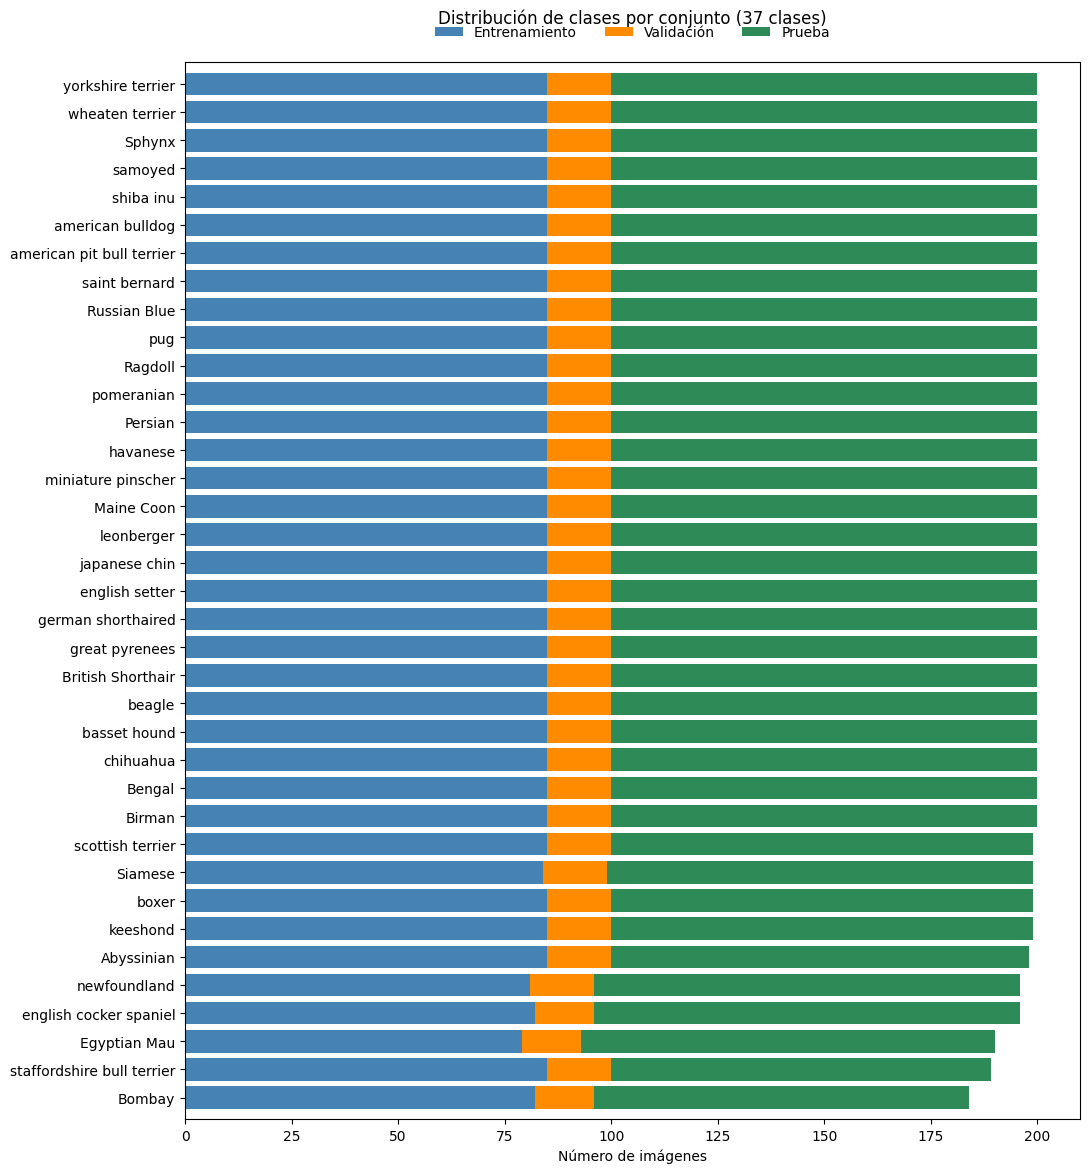

Imágenes del split train por especie: {'Dog': 2492, 'Cat': 1188}


In [26]:
conteos = pd.DataFrame(
    {
        "Entrenamiento": np.bincount(y_train_np, minlength=NUM_CLASES),
        "Validación": np.bincount(y_val_np, minlength=NUM_CLASES),
        "Prueba": np.bincount(y_test_np, minlength=NUM_CLASES),
    },
    index=pd.Index(ETIQUETAS_LEGIBLES, name="Clase"),
)
conteos["Total"] = conteos.sum(axis=1)
display(conteos.sort_values("Total"))
print("Mínimo / máximo de imágenes por clase en entrenamiento:", conteos["Entrenamiento"].min(), "/", conteos["Entrenamiento"].max())

orden = conteos.sort_values("Total").index
alto = max(4, 0.32 * NUM_CLASES)
fig, ax = plt.subplots(figsize=(11, alto))
izquierda = np.zeros(NUM_CLASES)
for conjunto, color in [("Entrenamiento", "steelblue"), ("Validación", "darkorange"), ("Prueba", "seagreen")]:
    valores = conteos.loc[orden, conjunto].values
    ax.barh(orden, valores, left=izquierda, color=color, label=conjunto)
    izquierda += valores
ax.set_xlabel("Número de imágenes")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=3, frameon=False)
ax.set_title(f"Distribución de clases por conjunto ({NUM_CLASES} clases)", pad=28)
ax.margins(y=0.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "01_distribucion_clases.png", dpi=150, bbox_inches="tight")
plt.show()

especies = pd.Series(etiquetas_train_completo[:, 1]).map(dict(enumerate(info.features["species"].names)))
print("Imágenes del split train por especie:", especies.value_counts().to_dict())

**Tamaño de las imágenes.** Las fotografías vienen con tamaños y proporciones distintos, así que hay que llevarlas a una resolución común antes de entrar a la red.

In [27]:
tamanos = np.array([ej["image"].shape[:2] for ej in tfds.as_numpy(ds_train_crudo.take(500))])
estadisticas = pd.DataFrame(tamanos, columns=["Alto", "Ancho"]).describe().round(1)
print("Tamaño de una muestra de 500 imágenes de entrenamiento (píxeles):")
display(estadisticas)

Tamaño de una muestra de 500 imágenes de entrenamiento (píxeles):


,Alto,Ancho
count,500.0,500.0
mean,387.3,431.3
std,126.2,146.5
min,143.0,114.0
25%,333.0,334.0
50%,375.0,500.0
75%,500.0,500.0
max,1920.0,2560.0


**Ejemplos del dataset.** Una imagen por clase (o varias por clase en el modo perro / gato), con su nombre.

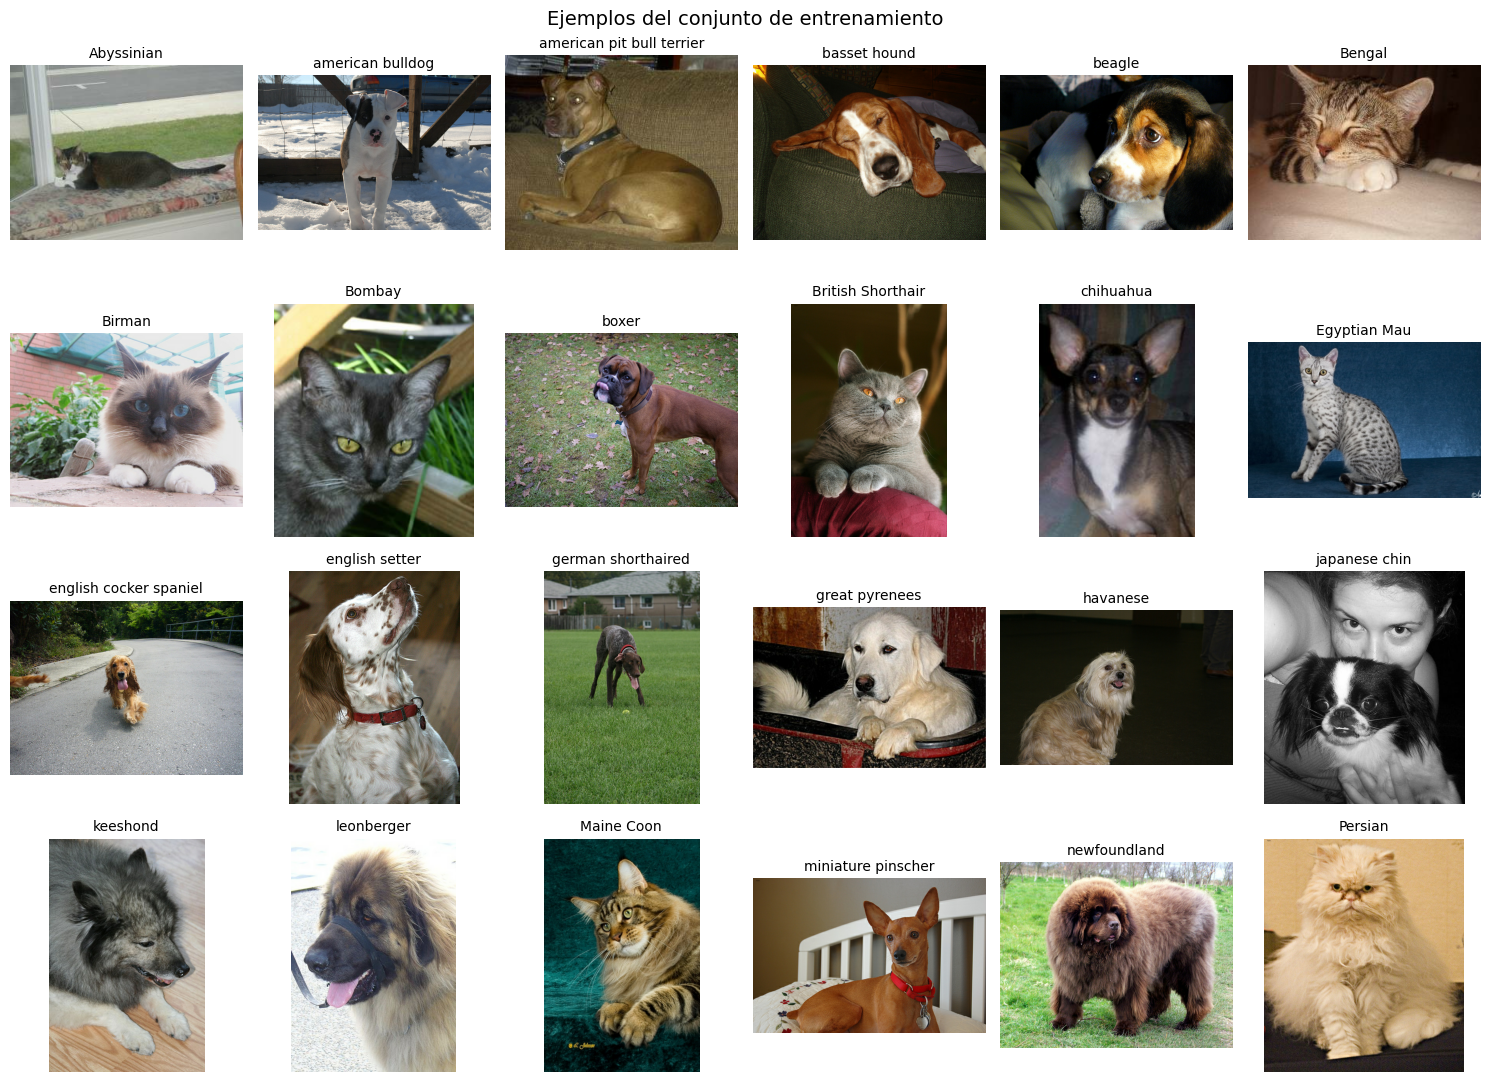

In [28]:
N_GRILLA = 24
por_clase = int(np.ceil(N_GRILLA / NUM_CLASES))
ejemplos = {}
for ejemplo in tfds.as_numpy(ds_train_crudo):
    clase = int(ejemplo[OBJETIVO])
    lista = ejemplos.setdefault(clase, [])
    if len(lista) < por_clase:
        lista.append(ejemplo["image"])
    if len(ejemplos) == NUM_CLASES and all(len(v) >= por_clase for v in ejemplos.values()):
        break

seleccion = [(clase, imagen) for clase in sorted(ejemplos) for imagen in ejemplos[clase]][:N_GRILLA]
fig, axes = plt.subplots(4, 6, figsize=(15, 11))
for ax in axes.flat:
    ax.axis("off")
for ax, (clase, imagen) in zip(axes.flat, seleccion):
    ax.imshow(imagen)
    ax.set_title(ETIQUETAS_LEGIBLES[clase], fontsize=10)
fig.suptitle("Ejemplos del conjunto de entrenamiento", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "02_ejemplos_dataset.png", dpi=150, bbox_inches="tight")
plt.show()

### 1.5 Pipeline de preprocesamiento

1. **Redimensionado a 224 × 224**, la resolución con la que se entrenó EfficientNetB0 en ImageNet.
2. **Caché en memoria.** Las imágenes redimensionadas se guardan como `uint8`, unos 1,1 GB para los tres conjuntos, así que la decodificación y el redimensionado se hacen una sola vez y no en cada época.
3. **Barajado** solo del entrenamiento, con semilla fija.
4. **Lotes de 32 imágenes.**
5. **`efficientnet.preprocess_input`.** En EfficientNet esta función es prácticamente la identidad, porque el modelo de Keras ya incluye internamente el reescalado y la normalización. Por eso la red recibe los píxeles en el rango **[0, 255]** y **no** se aplica un `Rescaling(1/255)` manual: hacerlo dejaría las imágenes casi negras para el backbone.
6. **`prefetch`**, para preparar el siguiente lote mientras la GPU entrena con el actual.

In [29]:
def redimensionar(ejemplo):
    imagen = tf.image.resize(ejemplo["image"], (TAM_IMAGEN, TAM_IMAGEN))
    imagen = tf.cast(tf.clip_by_value(tf.round(imagen), 0, 255), tf.uint8)  # uint8 ocupa 4 veces menos en caché
    return imagen, ejemplo[OBJETIVO]


def preprocesar(imagenes, etiquetas):
    return efficientnet.preprocess_input(tf.cast(imagenes, tf.float32)), etiquetas


def crear_pipeline(ds, entrenamiento=False):
    ds = ds.map(redimensionar, num_parallel_calls=AUTOTUNE).cache()
    if entrenamiento:
        ds = ds.shuffle(len(idx_train), seed=SEMILLA, reshuffle_each_iteration=True)
    return ds.batch(TAMANO_BATCH).map(preprocesar, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)


ds_train = crear_pipeline(ds_train_crudo, entrenamiento=True)
ds_val = crear_pipeline(ds_val_crudo)
ds_test = crear_pipeline(ds_test_crudo)

# Comprobaciones: forma, rango y orden de las etiquetas de prueba (se usa más adelante en la matriz de confusión)
imagenes, etiquetas = next(iter(ds_val))
print("Lote:", imagenes.shape, imagenes.dtype, "| rango:", float(tf.reduce_min(imagenes)), "-", float(tf.reduce_max(imagenes)))
y_test = np.concatenate([y.numpy() for _, y in ds_test])
assert np.array_equal(y_test, y_test_np), "El orden del conjunto de prueba no coincide"
print("Etiquetas de prueba verificadas:", len(y_test))

Lote: (32, 224, 224, 3) <dtype: 'float32'> | rango: 0.0 - 255.0
Etiquetas de prueba verificadas: 3669


## 2. Construcción de los modelos con una arquitectura convolucional preentrenada (b)

**Backbone: EfficientNetB0.** Es una CNN diseñada con *compound scaling*: escala de forma equilibrada la profundidad, el ancho y la resolución. Está construida con bloques MBConv (convoluciones *depthwise separable* con *squeeze-and-excitation*). Con unos 4 millones de parámetros sin la cabeza de clasificación, alcanza alrededor de 77 % de *top-1* en ImageNet, una muy buena relación entre precisión y costo para la GPU de Colab.

**Cabeza de clasificación:**

| Capa | Función |
|---|---|
| `GlobalAveragePooling2D` | Resume cada uno de los 1.280 mapas de características en un valor; menos parámetros que `Flatten` y menos sobreajuste |
| `Dropout(0,3)` | Regularización de la cabeza |
| `Dense(NUM_CLASES, softmax)` | Probabilidad de cada clase |

Una sola función construye los modelos de los cuatro experimentos. Así, todos comparten exactamente la misma arquitectura y solo cambia lo que se quiere estudiar: pesos aleatorios o de ImageNet, backbone congelado o parcialmente entrenable, y con o sin Data Augmentation.

Con pesos de ImageNet, el backbone se llama con `training=False`. Así las capas *BatchNormalization* conservan las estadísticas aprendidas en ImageNet incluso durante el *fine-tuning*. Si se actualizaran con lotes de 32 imágenes, se destruiría parte de lo aprendido.

In [30]:
DROPOUT_CABEZA = 0.3


def construir_modelo(nombre, pesos="imagenet", base_entrenable=False, aumentacion=None):
    # Construye EfficientNetB0 + cabeza de clasificación. pesos: "imagenet" o None (desde cero)
    base = keras.applications.EfficientNetB0(include_top=False, weights=pesos, input_shape=FORMA_ENTRADA)
    base.trainable = base_entrenable

    entradas = keras.Input(shape=FORMA_ENTRADA, name="imagen")
    x = aumentacion(entradas) if aumentacion is not None else entradas
    # Con pesos preentrenados, BatchNormalization queda siempre en modo inferencia
    x = base(x, training=False) if pesos == "imagenet" else base(x)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(DROPOUT_CABEZA, name="dropout")(x)
    salidas = keras.layers.Dense(NUM_CLASES, activation="softmax", name="clasificador")(x)
    return keras.Model(entradas, salidas, name=nombre)


def obtener_backbone(modelo):
    # Se busca por nombre: en el experimento D también es un submodelo la capa de aumentación
    return next(capa for capa in modelo.layers if capa.name.startswith("efficientnet"))


def contar_parametros(modelo):
    entrenables = int(sum(np.prod(w.shape) for w in modelo.trainable_weights))
    return int(modelo.count_params()), entrenables


modelo_referencia = construir_modelo("referencia_tl")
backbone = obtener_backbone(modelo_referencia)
print(f"Backbone: {backbone.name} | capas: {len(backbone.layers)} | parámetros: {backbone.count_params():,}")
print(f"Salida del backbone: {backbone.output.shape}  (mapas de 7x7 con 1.280 canales)")
modelo_referencia.summary()
del modelo_referencia, backbone

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Backbone: efficientnetb0 | capas: 238 | parámetros: 4,049,571
Salida del backbone: (None, 7, 7, 1280)  (mapas de 7x7 con 1.280 canales)


Model: "referencia_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clasificador (Dense)            │ (None, 37)             │        47,397 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,096,968 (15.63 MB)

 Trainable params: 47,397 (185.14 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

## 3. Funciones comunes de entrenamiento y evaluación (c)

Los cuatro experimentos se entrenan con la misma función:

- **EarlyStopping** sobre `val_loss`: detiene el entrenamiento cuando la validación deja de mejorar y restaura los mejores pesos.
- **ModelCheckpoint**: guarda en `modelos/` el mejor modelo de cada experimento según `val_loss`.
- El historial se guarda en `resultados/history_<experimento>.csv`.
- Al terminar se cargan los pesos del *checkpoint* y el modelo se evalúa en validación y prueba.

Todos usan la pérdida `sparse_categorical_crossentropy` (etiquetas enteras y salida *softmax*) y el optimizador Adam. Lo que cambia entre experimentos es la tasa de aprendizaje y qué capas se entrenan.

In [31]:
import time

modelos = {}
historiales = {}
resultados = {}


def compilar(modelo, tasa_aprendizaje):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=tasa_aprendizaje),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )


def entrenar_experimento(clave, descripcion, modelo, archivo, epocas, paciencia, tasa_aprendizaje):
    ruta = MOD_DIR / archivo
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(str(ruta), monitor="val_loss", save_best_only=True, verbose=0),
    ]
    inicio = time.time()
    history = modelo.fit(ds_train, validation_data=ds_val, epochs=epocas, callbacks=callbacks, verbose=2)
    duracion = time.time() - inicio

    historial = pd.DataFrame(history.history)
    historial.index = pd.RangeIndex(1, len(historial) + 1, name="época")
    historial.to_csv(RES_DIR / f"history_{clave}.csv")

    modelo.load_weights(ruta)  # mejor época según val_loss
    val_loss, val_acc = modelo.evaluate(ds_val, verbose=0)
    test_loss, test_acc = modelo.evaluate(ds_test, verbose=0)
    total, entrenables = contar_parametros(modelo)
    mejor_epoca = int(historial["val_loss"].idxmin())

    modelos[clave], historiales[clave] = modelo, historial
    resultados[clave] = {
        "descripcion": descripcion,
        "archivo": f"modelos/{archivo}",
        "tasa_aprendizaje": tasa_aprendizaje,
        "parametros_totales": total,
        "parametros_entrenables": entrenables,
        "epocas_entrenadas": len(historial),
        "mejor_epoca": mejor_epoca,
        "train_accuracy_mejor_epoca": float(historial.loc[mejor_epoca, "accuracy"]),
        "val_loss": float(val_loss),
        "val_accuracy": float(val_acc),
        "test_loss": float(test_loss),
        "test_accuracy": float(test_acc),
        "tiempo_entrenamiento_s": round(duracion, 1),
    }
    print(f"\n{descripcion}: val_accuracy = {val_acc:.4f} | test_accuracy = {test_acc:.4f} | "
          f"épocas = {len(historial)} (mejor: {mejor_epoca}) | tiempo = {duracion / 60:.1f} min")

## 4. Experimento A – CNN entrenada desde cero (línea base)

La misma EfficientNetB0, pero con **pesos aleatorios** (`weights=None`) y **todas las capas entrenables**. Como la arquitectura es idéntica a la de los demás experimentos, la diferencia entre A y B se debe únicamente a los pesos de ImageNet, lo que aísla el efecto del *Transfer Learning*.

Se espera un desempeño bajo: unas 3.100 imágenes de entrenamiento son muy pocas para aprender desde cero los filtros de una red con 4 millones de parámetros y distinguir 37 razas con diferencias sutiles.

| Hiperparámetro | Valor |
|---|---|
| Tasa de aprendizaje | 0,001 (Adam) |
| Épocas máximas | 30 |
| Paciencia de *early stopping* | 6 |

In [32]:
EPOCAS_A, PACIENCIA_A, LR_A = 30, 6, 1e-3

modelo_A = construir_modelo("expA_cnn_scratch", pesos=None, base_entrenable=True)
compilar(modelo_A, LR_A)
entrenar_experimento("expA", "A – CNN desde cero", modelo_A, "t2_expA_cnn_scratch.keras", EPOCAS_A, PACIENCIA_A, LR_A)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


98/98 - 304s - 3s/step - accuracy: 0.0428 - loss: 3.8314 - val_accuracy: 0.0272 - val_loss: 4.0891
Epoch 2/30
98/98 - 12s - 127ms/step - accuracy: 0.0540 - loss: 3.6083 - val_accuracy: 0.0272 - val_loss: 4.4745
Epoch 3/30
98/98 - 13s - 128ms/step - accuracy: 0.0639 - loss: 3.4741 - val_accuracy: 0.0254 - val_loss: 5.8083
Epoch 4/30
98/98 - 13s - 129ms/step - accuracy: 0.0882 - loss: 3.3100 - val_accuracy: 0.0290 - val_loss: 4.9427
Epoch 5/30
98/98 - 14s - 141ms/step - accuracy: 0.1250 - loss: 3.1499 - val_accuracy: 0.0543 - val_loss: 3.8845
Epoch 6/30
98/98 - 14s - 144ms/step - accuracy: 0.1579 - loss: 2.9550 - val_accuracy: 0.0906 - val_loss: 3.7079
Epoch 7/30
98/98 - 12s - 126ms/step - accuracy: 0.2097 - loss: 2.7222 - val_accuracy: 0.1214 - val_loss: 4.5495
Epoch 8/30
98/98 - 13s - 129ms/step - accuracy: 0.2650 - loss: 2.4893 - val_accuracy: 0.1322 - val_loss: 3.8321
Epoch 9/30
98/98 - 12s - 126ms/step - accuracy: 0.3098 - loss: 2.2308 - val_accuracy: 0.1304 - val_loss: 4.0978
Epoch

## 5. Experimento B – Transfer Learning con backbone congelado (*feature extraction*)

EfficientNetB0 con **pesos de ImageNet** y **todas sus capas congeladas**. Funciona como un extractor de características fijo y solo se entrena la cabeza de clasificación (unos 47 mil parámetros para 37 clases). La idea es que los filtros aprendidos en ImageNet (bordes, texturas, formas, partes de animales) ya sirven para describir mascotas.

| Hiperparámetro | Valor |
|---|---|
| Tasa de aprendizaje | 0,001 (Adam) |
| Épocas máximas | 20 |
| Paciencia de *early stopping* | 4 |

In [33]:
EPOCAS_B, PACIENCIA_B, LR_B = 20, 4, 1e-3

modelo_B = construir_modelo("expB_tl_frozen", pesos="imagenet", base_entrenable=False)
compilar(modelo_B, LR_B)
entrenar_experimento("expB", "B – TL congelado", modelo_B, "t2_expB_tl_frozen.keras", EPOCAS_B, PACIENCIA_B, LR_B)

Epoch 1/20


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


98/98 - 51s - 520ms/step - accuracy: 0.6720 - loss: 1.6005 - val_accuracy: 0.8877 - val_loss: 0.6169
Epoch 2/20
98/98 - 5s - 50ms/step - accuracy: 0.9028 - loss: 0.4878 - val_accuracy: 0.9130 - val_loss: 0.3718
Epoch 3/20
98/98 - 5s - 53ms/step - accuracy: 0.9325 - loss: 0.3171 - val_accuracy: 0.9239 - val_loss: 0.2932
Epoch 4/20
98/98 - 5s - 54ms/step - accuracy: 0.9437 - loss: 0.2489 - val_accuracy: 0.9293 - val_loss: 0.2577
Epoch 5/20
98/98 - 5s - 49ms/step - accuracy: 0.9572 - loss: 0.1981 - val_accuracy: 0.9366 - val_loss: 0.2304
Epoch 6/20
98/98 - 5s - 51ms/step - accuracy: 0.9674 - loss: 0.1637 - val_accuracy: 0.9330 - val_loss: 0.2157
Epoch 7/20
98/98 - 5s - 53ms/step - accuracy: 0.9757 - loss: 0.1410 - val_accuracy: 0.9366 - val_loss: 0.2000
Epoch 8/20
98/98 - 5s - 49ms/step - accuracy: 0.9786 - loss: 0.1216 - val_accuracy: 0.9402 - val_loss: 0.1897
Epoch 9/20
98/98 - 5s - 52ms/step - accuracy: 0.9840 - loss: 0.1085 - val_accuracy: 0.9420 - val_loss: 0.1829
Epoch 10/20
98/98 -

## 6. Experimento C – Transfer Learning + fine-tuning

El *fine-tuning* parte del **mejor modelo del experimento B**: la cabeza ya está entrenada, así que sus gradientes iniciales son pequeños y no dañan los pesos preentrenados. Luego:

1. Se descongelan las **últimas 40 capas** del backbone, las más especializadas, que son las que más se benefician de adaptarse a razas de mascotas. Las primeras capas detectan bordes y texturas genéricas y se mantienen congeladas.
2. Las capas **BatchNormalization** siguen congeladas.
3. Se entrena con una **tasa de aprendizaje 100 veces menor (0,00001)**, para ajustar los pesos sin borrar lo aprendido en ImageNet.

| Hiperparámetro | Valor |
|---|---|
| Punto de partida | Mejor modelo del experimento B |
| Capas descongeladas | Últimas 40 del backbone (sin BatchNormalization) |
| Tasa de aprendizaje | 0,00001 (Adam) |
| Épocas máximas | 15 |
| Paciencia de *early stopping* | 4 |

El experimento D usa exactamente esta misma configuración. La única diferencia entre C y D es el Data Augmentation.

In [34]:
EPOCAS_FT, PACIENCIA_FT, LR_FT = 15, 4, 1e-5
CAPAS_DESCONGELADAS = 40


def copiar_pesos(origen, destino):
    # Copia backbone y cabeza del modelo origen (mejor modelo de B) al modelo destino
    obtener_backbone(destino).set_weights(obtener_backbone(origen).get_weights())
    destino.get_layer("clasificador").set_weights(origen.get_layer("clasificador").get_weights())


def preparar_fine_tuning(modelo, n_capas=CAPAS_DESCONGELADAS):
    base = obtener_backbone(modelo)
    base.trainable = True
    for capa in base.layers[:-n_capas]:
        capa.trainable = False
    for capa in base.layers:
        if isinstance(capa, keras.layers.BatchNormalization):
            capa.trainable = False
    entrenables = sum(capa.trainable for capa in base.layers if capa.weights)
    total, entrenables_param = contar_parametros(modelo)
    print(f"Capas del backbone con pesos entrenables: {entrenables} de {sum(1 for c in base.layers if c.weights)} "
          f"| parámetros entrenables del modelo: {entrenables_param:,} de {total:,}")


modelo_C = construir_modelo("expC_tl_finetune", pesos="imagenet")
copiar_pesos(modelos["expB"], modelo_C)
preparar_fine_tuning(modelo_C)
compilar(modelo_C, LR_FT)
print("Accuracy de validación al iniciar (debe coincidir con B):", round(modelo_C.evaluate(ds_val, verbose=0)[1], 4))

entrenar_experimento("expC", "C – TL + fine-tuning", modelo_C, "t2_expC_tl_finetune.keras", EPOCAS_FT, PACIENCIA_FT, LR_FT)

Capas del backbone con pesos entrenables: 14 de 131 | parámetros entrenables del modelo: 2,084,917 de 4,096,968
Accuracy de validación al iniciar (debe coincidir con B): 0.9438
Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


98/98 - 43s - 439ms/step - accuracy: 0.9933 - loss: 0.0419 - val_accuracy: 0.9457 - val_loss: 0.1504
Epoch 2/15
98/98 - 10s - 103ms/step - accuracy: 0.9958 - loss: 0.0319 - val_accuracy: 0.9438 - val_loss: 0.1483
Epoch 3/15
98/98 - 5s - 46ms/step - accuracy: 0.9971 - loss: 0.0273 - val_accuracy: 0.9438 - val_loss: 0.1493
Epoch 4/15
98/98 - 6s - 60ms/step - accuracy: 0.9952 - loss: 0.0250 - val_accuracy: 0.9420 - val_loss: 0.1477
Epoch 5/15
98/98 - 5s - 46ms/step - accuracy: 0.9939 - loss: 0.0286 - val_accuracy: 0.9420 - val_loss: 0.1508
Epoch 6/15
98/98 - 5s - 54ms/step - accuracy: 0.9984 - loss: 0.0214 - val_accuracy: 0.9457 - val_loss: 0.1525
Epoch 7/15
98/98 - 5s - 50ms/step - accuracy: 0.9962 - loss: 0.0227 - val_accuracy: 0.9457 - val_loss: 0.1490
Epoch 8/15
98/98 - 5s - 55ms/step - accuracy: 0.9958 - loss: 0.0207 - val_accuracy: 0.9511 - val_loss: 0.1448
Epoch 9/15
98/98 - 9s - 97ms/step - accuracy: 0.9984 - loss: 0.0175 - val_accuracy: 0.9402 - val_loss: 0.1452
Epoch 10/15
98/98

## 7. Data Augmentation y Experimento D (d)

### 7.1 Capas de Data Augmentation

El Data Augmentation genera, en cada época, versiones distintas de las imágenes de entrenamiento con transformaciones que no cambian la raza. Así el modelo ve más variedad y memoriza menos.

| Capa | Transformación | Justificación |
|---|---|---|
| `RandomFlip("horizontal")` | Espejo horizontal | Una mascota mirando a la izquierda o a la derecha es la misma raza |
| `RandomRotation(0.1)` | Rotación de hasta ±36° | Fotos tomadas con la cámara inclinada |
| `RandomZoom(0.15)` | Acercamiento o alejamiento de hasta 15 % | Distintas distancias y encuadres |
| `RandomContrast(0.2)` | Contraste ± 20 % | Distintas condiciones de iluminación |

Las capas van **dentro del modelo**, justo después de la entrada. Keras solo las activa durante `fit` (entrenamiento) y las desactiva automáticamente en validación, evaluación y predicción. Por eso el aumento se aplica **solo a los datos de entrenamiento**.

No se usa el volteo vertical: una mascota cabeza abajo es una imagen irreal para este problema.

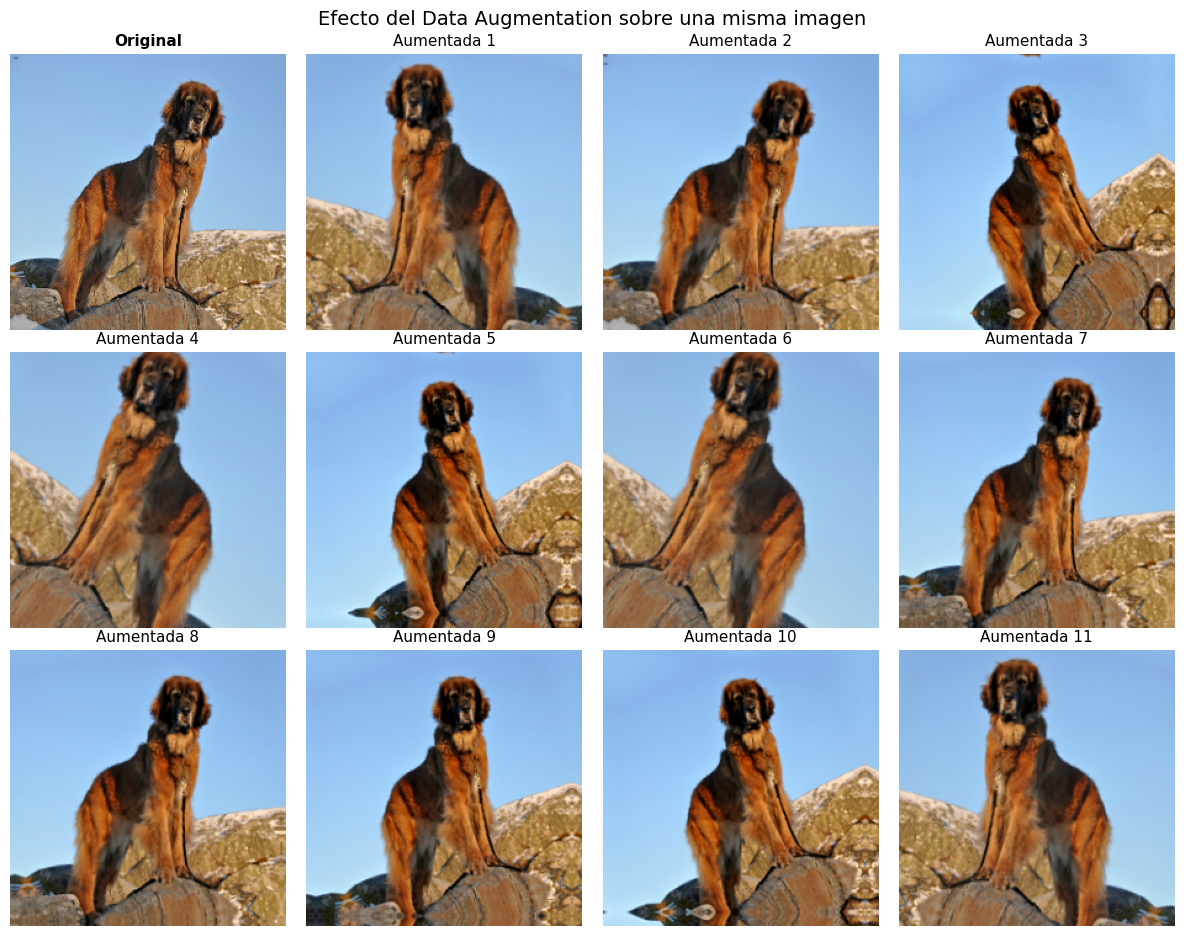

In [35]:
aumentacion = keras.Sequential(
    [
        keras.layers.RandomFlip("horizontal", seed=SEMILLA),
        keras.layers.RandomRotation(0.1, seed=SEMILLA),
        keras.layers.RandomZoom(0.15, seed=SEMILLA),
        keras.layers.RandomContrast(0.2, seed=SEMILLA),  # opera sobre el rango [0, 255] que recibe el modelo
    ],
    name="aumentacion",
)

# Visualización del efecto sobre una imagen de entrenamiento
imagen_ejemplo = next(iter(ds_train))[0][:1]
fig, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for i, ax in enumerate(axes.flat):
    vista = imagen_ejemplo if i == 0 else aumentacion(imagen_ejemplo, training=True)
    ax.imshow(np.clip(vista[0].numpy(), 0, 255).astype("uint8"))
    ax.set_title("Original" if i == 0 else f"Aumentada {i}", fontsize=11, fontweight="bold" if i == 0 else None)
    ax.axis("off")
fig.suptitle("Efecto del Data Augmentation sobre una misma imagen", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_data_augmentation.png", dpi=150, bbox_inches="tight")
plt.show()

### 7.2 Experimento D – Transfer Learning + fine-tuning + Data Augmentation

Misma configuración que el experimento C: parte del mejor modelo de B, descongela las últimas 40 capas y usa una tasa de aprendizaje de 0,00001 durante máximo 15 épocas. La única diferencia es la capa de aumentación al inicio del modelo. Así, la comparación C vs. D mide solamente el efecto del Data Augmentation.

In [36]:
modelo_D = construir_modelo("expD_tl_finetune_da", pesos="imagenet", aumentacion=aumentacion)
copiar_pesos(modelos["expB"], modelo_D)
preparar_fine_tuning(modelo_D)
compilar(modelo_D, LR_FT)
print("Accuracy de validación al iniciar (debe coincidir con B):", round(modelo_D.evaluate(ds_val, verbose=0)[1], 4))

entrenar_experimento("expD", "D – TL + fine-tuning + DA", modelo_D, "t2_expD_tl_finetune_da.keras", EPOCAS_FT, PACIENCIA_FT, LR_FT)

Capas del backbone con pesos entrenables: 14 de 131 | parámetros entrenables del modelo: 2,084,917 de 4,096,968
Accuracy de validación al iniciar (debe coincidir con B): 0.9438
Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


98/98 - 25s - 255ms/step - accuracy: 0.9527 - loss: 0.1656 - val_accuracy: 0.9330 - val_loss: 0.1606
Epoch 2/15
98/98 - 10s - 99ms/step - accuracy: 0.9549 - loss: 0.1499 - val_accuracy: 0.9312 - val_loss: 0.1636
Epoch 3/15
98/98 - 10s - 105ms/step - accuracy: 0.9594 - loss: 0.1359 - val_accuracy: 0.9330 - val_loss: 0.1657
Epoch 4/15
98/98 - 10s - 101ms/step - accuracy: 0.9629 - loss: 0.1252 - val_accuracy: 0.9348 - val_loss: 0.1620
Epoch 5/15
98/98 - 11s - 113ms/step - accuracy: 0.9661 - loss: 0.1129 - val_accuracy: 0.9366 - val_loss: 0.1589
Epoch 6/15
98/98 - 12s - 118ms/step - accuracy: 0.9629 - loss: 0.1120 - val_accuracy: 0.9348 - val_loss: 0.1588
Epoch 7/15
98/98 - 19s - 190ms/step - accuracy: 0.9687 - loss: 0.1088 - val_accuracy: 0.9384 - val_loss: 0.1603
Epoch 8/15
98/98 - 11s - 111ms/step - accuracy: 0.9693 - loss: 0.1052 - val_accuracy: 0.9384 - val_loss: 0.1584
Epoch 9/15
98/98 - 10s - 100ms/step - accuracy: 0.9731 - loss: 0.0918 - val_accuracy: 0.9366 - val_loss: 0.1587
Epoc

## 8. Comparación de experimentos (e)

### 8.1 Tabla comparativa

La columna **Brecha train−val** es la diferencia entre la accuracy de entrenamiento y la de validación en la mejor época; sirve como indicador de sobreajuste. En el experimento D, la accuracy de entrenamiento se mide sobre imágenes aumentadas, que son más difíciles, así que su brecha tiende a ser menor.

In [37]:
tabla = pd.DataFrame(resultados).T
tabla["brecha_train_val"] = tabla["train_accuracy_mejor_epoca"] - tabla["val_accuracy"]
tabla_comparativa = tabla[
    ["descripcion", "test_accuracy", "test_loss", "val_accuracy", "brecha_train_val",
     "parametros_totales", "parametros_entrenables", "epocas_entrenadas", "mejor_epoca",
     "tasa_aprendizaje", "tiempo_entrenamiento_s"]
].rename(columns={
    "descripcion": "Experimento", "test_accuracy": "Accuracy test", "test_loss": "Loss test",
    "val_accuracy": "Accuracy val", "brecha_train_val": "Brecha train-val",
    "parametros_totales": "Parámetros totales", "parametros_entrenables": "Parámetros entrenables",
    "epocas_entrenadas": "Épocas", "mejor_epoca": "Mejor época", "tasa_aprendizaje": "Tasa de aprendizaje",
    "tiempo_entrenamiento_s": "Tiempo (s)",
})
tabla_comparativa.index.name = "Clave"
tabla_comparativa.to_csv(RES_DIR / "tabla_comparativa.csv", encoding="utf-8")
# Copia con formato legible solo para mostrar (el CSV conserva los valores numéricos)
vista = tabla_comparativa.copy()
formatos = {"Accuracy test": "{:.2%}", "Loss test": "{:.4f}", "Accuracy val": "{:.2%}", "Brecha train-val": "{:+.2%}",
            "Parámetros totales": "{:,}", "Parámetros entrenables": "{:,}", "Tasa de aprendizaje": "{:g}"}
for columna, formato in formatos.items():
    vista[columna] = vista[columna].map(formato.format)
display(vista)

,Experimento,Accuracy test,Loss test,Accuracy val,Brecha train-val,Parámetros totales,Parámetros entrenables,Épocas,Mejor época,Tasa de aprendizaje,Tiempo (s)
Clave,,,,,,,,,,,
expA,A – CNN desde cero,7.47%,3.8101,9.06%,+6.73%,"4,096,968","4,054,945",12,6,0.001,444.5
expB,B – TL congelado,92.12%,0.2437,94.38%,+5.17%,"4,096,968","47,397",20,18,0.001,144.0
expC,C – TL + fine-tuning,91.96%,0.2619,95.11%,+4.48%,"4,096,968","2,084,917",12,8,1e-05,107.9
expD,D – TL + fine-tuning + DA,91.52%,0.2608,93.84%,+3.09%,"4,096,968","2,084,917",12,8,1e-05,146.9


### 8.2 Curvas de entrenamiento

En C y D las épocas corresponden solo a la fase de *fine-tuning*, que continúa desde el mejor punto de B.

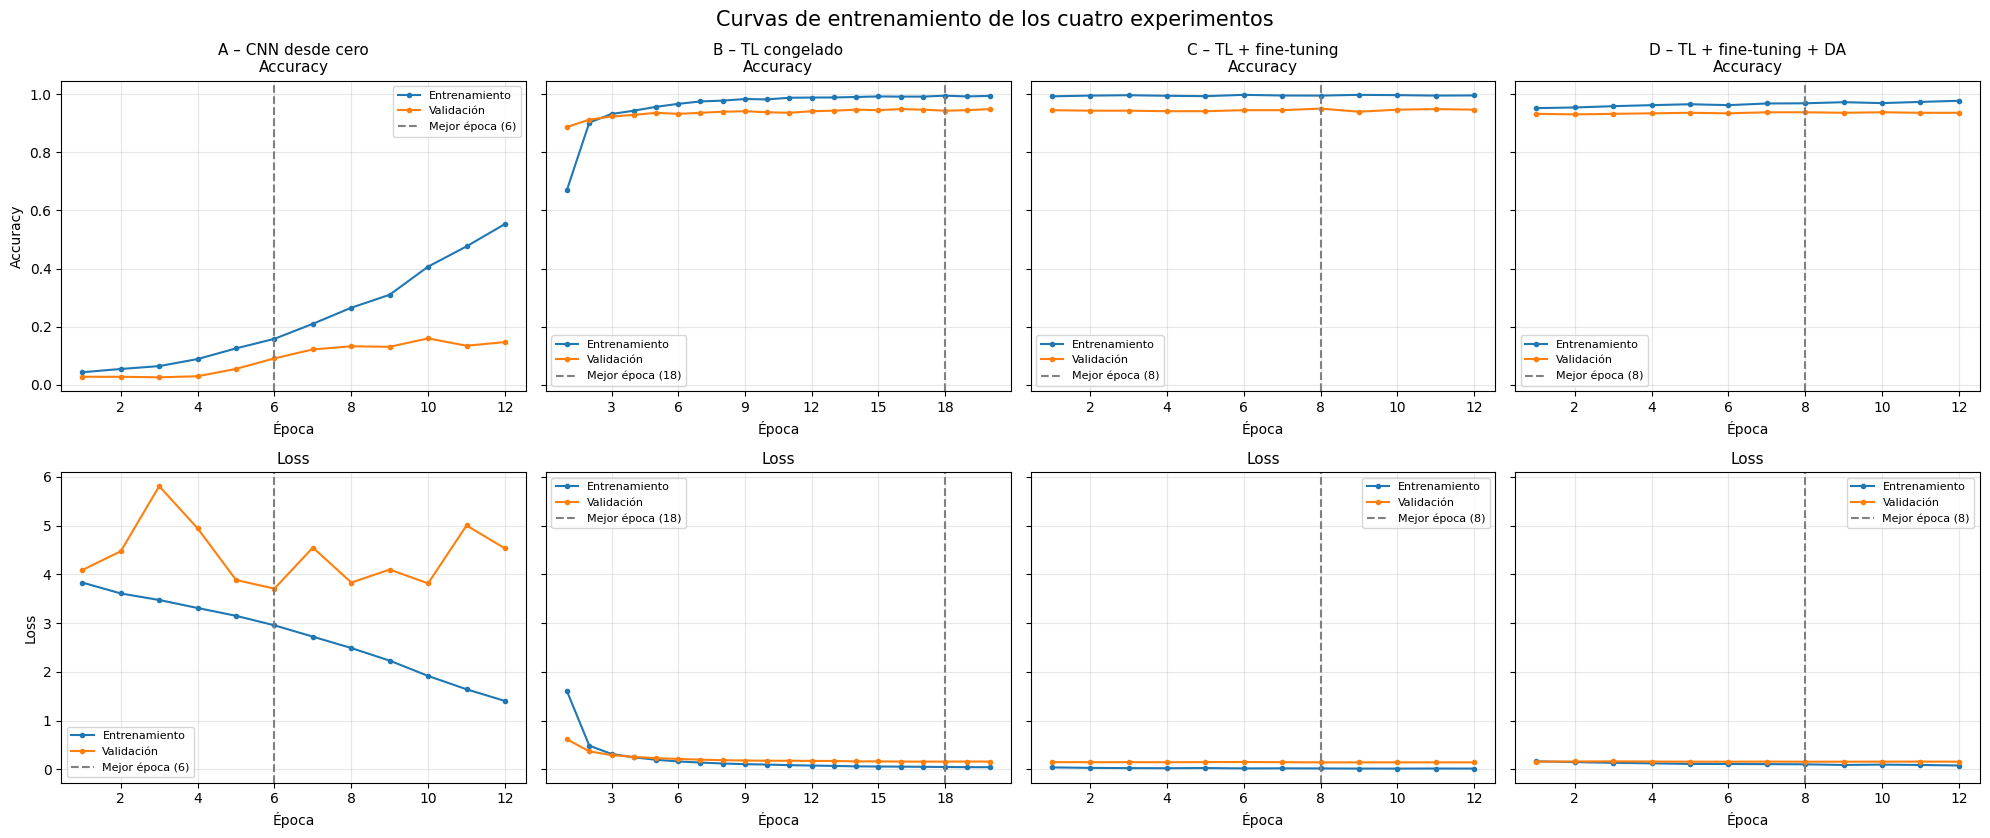

In [38]:
import matplotlib.ticker

claves = list(resultados)
fig, axes = plt.subplots(2, len(claves), figsize=(5 * len(claves), 8.5), sharey="row")
for j, clave in enumerate(claves):
    historial = historiales[clave]
    mejor = resultados[clave]["mejor_epoca"]
    for i, (metrica, nombre) in enumerate([("accuracy", "Accuracy"), ("loss", "Loss")]):
        ax = axes[i, j]
        ax.plot(historial.index, historial[metrica], marker="o", markersize=3, label="Entrenamiento")
        ax.plot(historial.index, historial[f"val_{metrica}"], marker="o", markersize=3, label="Validación")
        ax.axvline(mejor, color="gray", linestyle="--", label=f"Mejor época ({mejor})")
        ax.set_title(f"{resultados[clave]['descripcion']}\n{nombre}" if i == 0 else nombre, fontsize=11)
        ax.set_xlabel("Época")
        ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
        ax.grid(alpha=0.3)
        if j == 0:
            ax.set_ylabel(nombre)
        ax.legend(fontsize=8)
fig.suptitle("Curvas de entrenamiento de los cuatro experimentos", fontsize=15)
fig.tight_layout()
fig.savefig(FIG_DIR / "04_curvas_entrenamiento.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.3 Accuracy de prueba por experimento

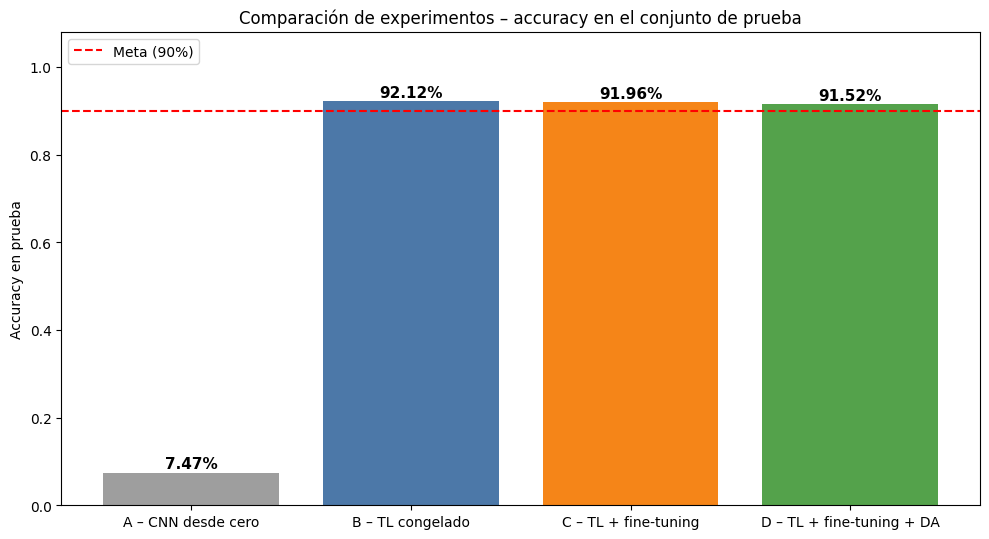

In [39]:
fig, ax = plt.subplots(figsize=(10, 5.5))
nombres = [resultados[c]["descripcion"] for c in claves]
valores = [resultados[c]["test_accuracy"] for c in claves]
barras = ax.bar(nombres, valores, color=["#9e9e9e", "#4c78a8", "#f58518", "#54a24b"][: len(claves)])
ax.axhline(META_ACCURACY, color="red", linestyle="--", label=f"Meta ({META_ACCURACY:.0%})")
for barra, valor in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, valor + 0.01, f"{valor:.2%}", ha="center", fontsize=11, fontweight="bold")
ax.set_ylim(0, 1.08)
ax.set_ylabel("Accuracy en prueba")
ax.set_title("Comparación de experimentos – accuracy en el conjunto de prueba")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG_DIR / "05_comparacion_experimentos.png", dpi=150, bbox_inches="tight")
plt.show()

### 8.4 Mejor modelo: matriz de confusión y reporte por clase

El mejor experimento se elige por **accuracy de validación**, no de prueba. El conjunto de prueba debe quedar fuera de toda decisión; si se usara para elegir el modelo, su accuracy dejaría de ser una estimación honesta del desempeño con datos nuevos.

Mejor experimento (por validación): C – TL + fine-tuning
Accuracy en prueba: 0.9196
Accuracy a partir de las predicciones: 0.9196


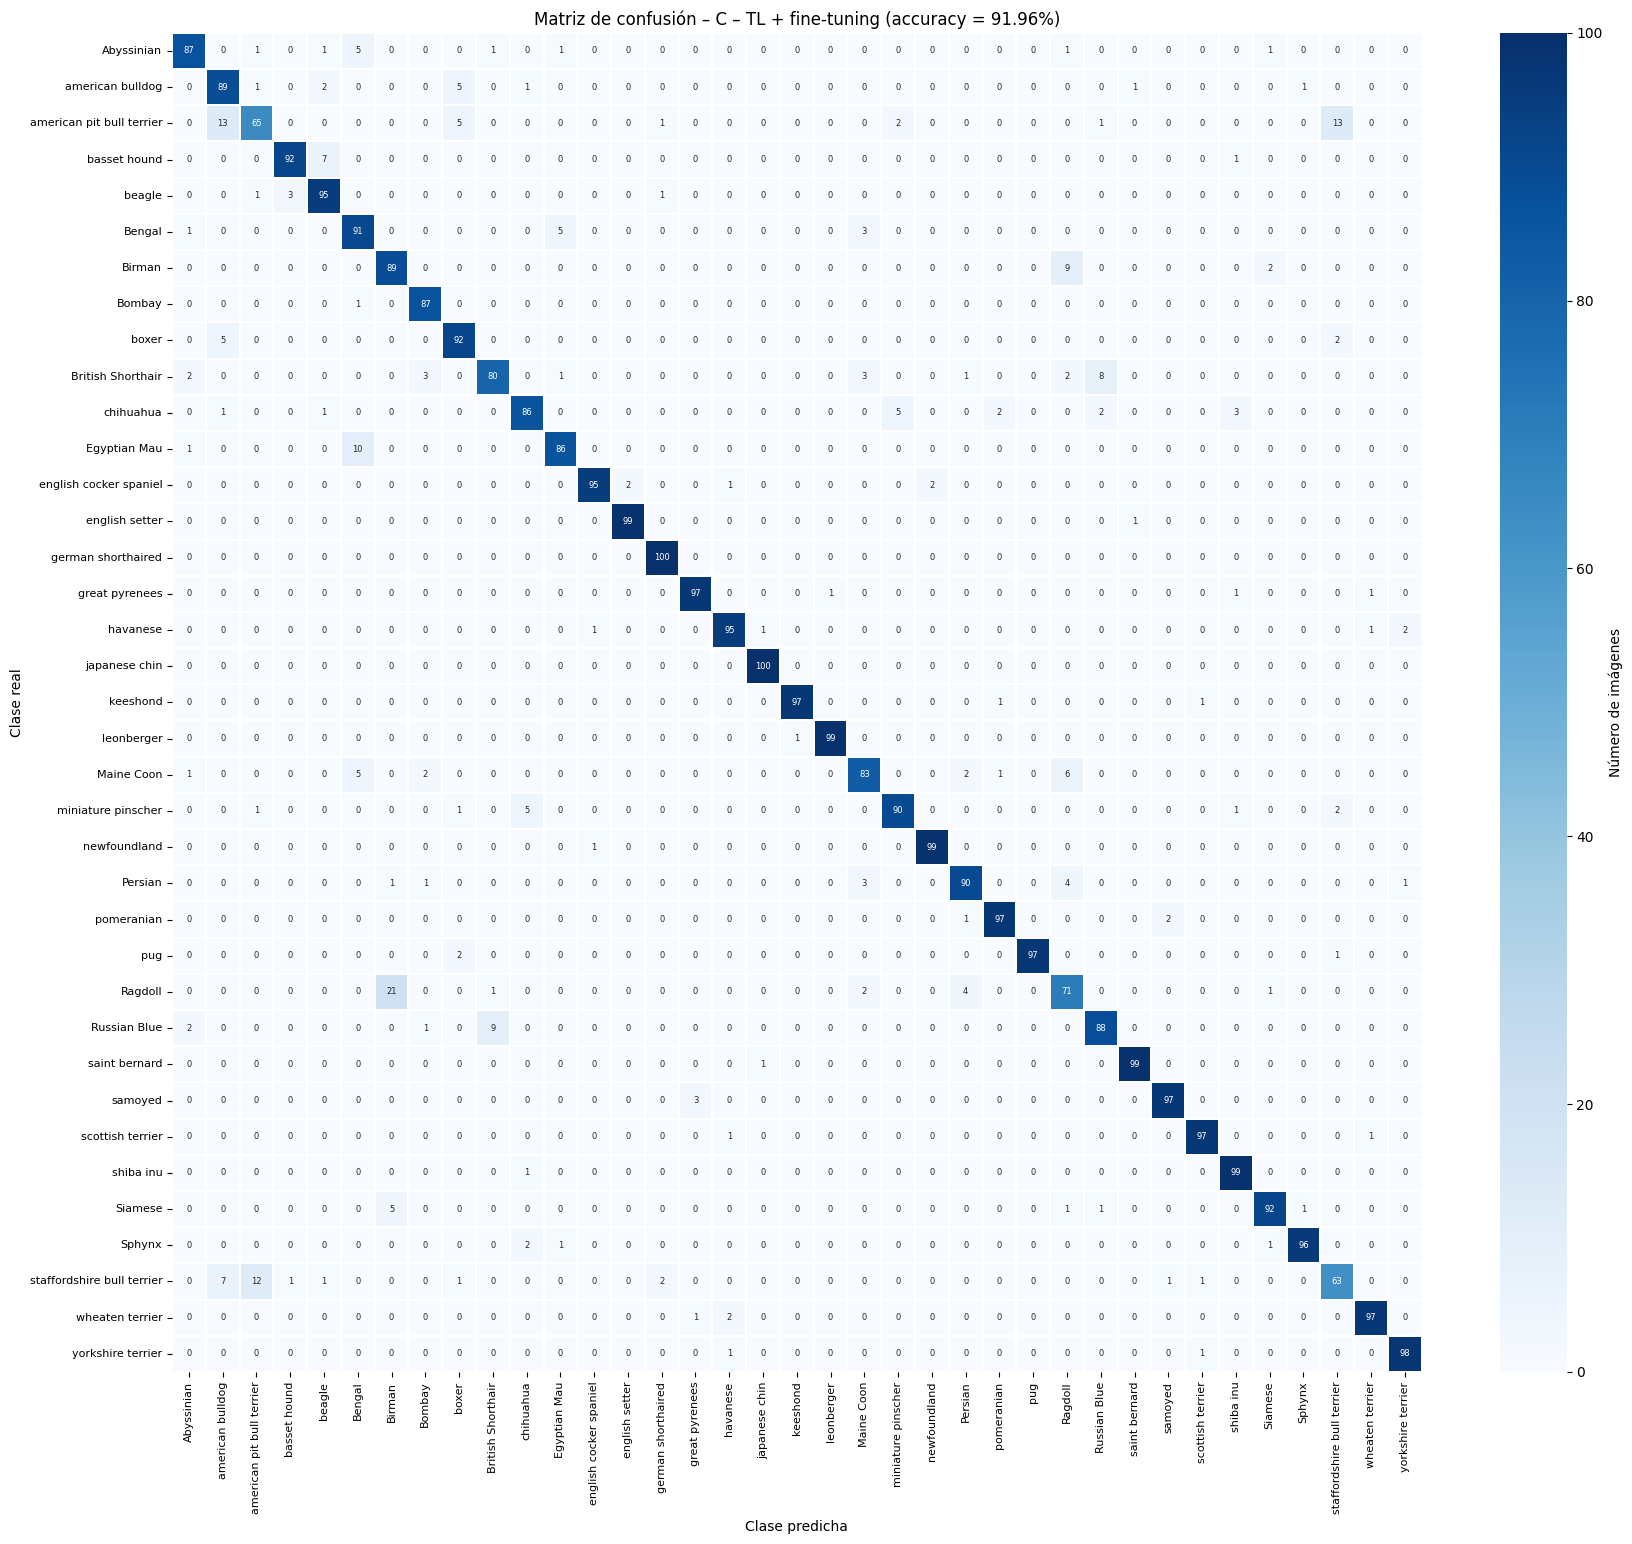

                            precision    recall  f1-score   support

                Abyssinian     0.9255    0.8878    0.9062        98
          american bulldog     0.7739    0.8900    0.8279       100
 american pit bull terrier     0.8025    0.6500    0.7182       100
              basset hound     0.9583    0.9200    0.9388       100
                    beagle     0.8879    0.9500    0.9179       100
                    Bengal     0.8125    0.9100    0.8585       100
                    Birman     0.7672    0.8900    0.8241       100
                    Bombay     0.9255    0.9886    0.9560        88
                     boxer     0.8679    0.9293    0.8976        99
         British Shorthair     0.8791    0.8000    0.8377       100
                 chihuahua     0.9053    0.8600    0.8821       100
              Egyptian Mau     0.9149    0.8866    0.9005        97
    english cocker spaniel     0.9794    0.9500    0.9645       100
            english setter     0.9802    0.9900

2870

In [40]:
from sklearn.metrics import classification_report, confusion_matrix

MEJOR = max(resultados, key=lambda c: resultados[c]["val_accuracy"])
modelo_mejor = modelos[MEJOR]
print(f"Mejor experimento (por validación): {resultados[MEJOR]['descripcion']}")
print(f"Accuracy en prueba: {resultados[MEJOR]['test_accuracy']:.4f}")

probabilidades = modelo_mejor.predict(ds_test, verbose=0)
y_pred = probabilidades.argmax(axis=1)
confianza = probabilidades.max(axis=1)
print(f"Accuracy a partir de las predicciones: {(y_pred == y_test).mean():.4f}")

matriz = confusion_matrix(y_test, y_pred, labels=np.arange(NUM_CLASES))
lado = max(7, 0.42 * NUM_CLASES)
fig, ax = plt.subplots(figsize=(lado + 2, lado))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues", linewidths=0.3, linecolor="white",
    xticklabels=ETIQUETAS_LEGIBLES, yticklabels=ETIQUETAS_LEGIBLES,
    annot_kws={"size": 6 if NUM_CLASES > 10 else 14}, cbar_kws={"label": "Número de imágenes"}, ax=ax,
)
ax.set_xlabel("Clase predicha")
ax.set_ylabel("Clase real")
ax.set_title(f"Matriz de confusión – {resultados[MEJOR]['descripcion']} (accuracy = {resultados[MEJOR]['test_accuracy']:.2%})")
plt.setp(ax.get_xticklabels(), rotation=90, fontsize=8 if NUM_CLASES > 10 else 12)
plt.setp(ax.get_yticklabels(), rotation=0, fontsize=8 if NUM_CLASES > 10 else 12)
fig.tight_layout()
fig.savefig(FIG_DIR / "06_matriz_confusion_mejor.png", dpi=150, bbox_inches="tight")
plt.show()

reporte = classification_report(y_test, y_pred, labels=np.arange(NUM_CLASES), target_names=ETIQUETAS_LEGIBLES, digits=4)
print(reporte)
(RES_DIR / "classification_report_mejor.txt").write_text(
    f"Taller 2 – {resultados[MEJOR]['descripcion']}: reporte de clasificación (conjunto de prueba)\n\n" + reporte,
    encoding="utf-8",
)

### 8.5 Clases que más se confunden

In [41]:
errores_matriz = matriz.copy()
np.fill_diagonal(errores_matriz, 0)
pares = pd.DataFrame(
    [
        (ETIQUETAS_LEGIBLES[r], ETIQUETAS_LEGIBLES[p], errores_matriz[r, p])
        for r in range(NUM_CLASES) for p in range(NUM_CLASES) if errores_matriz[r, p] > 0
    ],
    columns=["Real", "Predicho", "Errores"],
).sort_values("Errores", ascending=False).head(12).reset_index(drop=True)
print("Confusiones más frecuentes (real → predicho):")
display(pares)

por_clase = pd.DataFrame(
    {"Muestras": matriz.sum(axis=1), "Aciertos": np.diag(matriz)}, index=pd.Index(ETIQUETAS_LEGIBLES, name="Clase")
)
por_clase["Errores"] = por_clase["Muestras"] - por_clase["Aciertos"]
por_clase["Accuracy (%)"] = (por_clase["Aciertos"] / por_clase["Muestras"] * 100).round(2)
print("Clases con menor accuracy:")
display(por_clase.sort_values("Accuracy (%)").head(10))

# Errores entre especies (un perro clasificado como gato o al revés) cuando la tarea es por razas
if OBJETIVO == "label":
    especie_de_raza = pd.Series(etiquetas_test[:, 1], index=etiquetas_test[:, 0]).groupby(level=0).first()
    cruzados = int((especie_de_raza.loc[y_pred].values != especie_de_raza.loc[y_test].values).sum())
    print(f"Errores entre especies: {cruzados} de {int((y_pred != y_test).sum())} errores totales")

Confusiones más frecuentes (real → predicho):


,Real,Predicho,Errores
0,Ragdoll,Birman,21
1,american pit bull terrier,american bulldog,13
2,american pit bull terrier,staffordshire bull terrier,13
3,staffordshire bull terrier,american pit bull terrier,12
4,Egyptian Mau,Bengal,10
5,Birman,Ragdoll,9
6,Russian Blue,British Shorthair,9
7,British Shorthair,Russian Blue,8
8,staffordshire bull terrier,american bulldog,7
9,basset hound,beagle,7


Clases con menor accuracy:


,Muestras,Aciertos,Errores,Accuracy (%)
Clase,,,,
american pit bull terrier,100,65,35,65.00
staffordshire bull terrier,89,63,26,70.79
Ragdoll,100,71,29,71.00
British Shorthair,100,80,20,80.00
Maine Coon,100,83,17,83.00
chihuahua,100,86,14,86.00
Russian Blue,100,88,12,88.00
Egyptian Mau,97,86,11,88.66
Abyssinian,98,87,11,88.78


Errores entre especies: 11 de 295 errores totales


## 9. Análisis técnico (f)

La siguiente celda calcula el aporte de cada técnica en puntos porcentuales de accuracy de prueba. El análisis se apoya en esas cifras y en la tabla y figuras de la sección 8.

In [42]:
acc = {clave: resultados[clave]["test_accuracy"] for clave in resultados}
efectos = pd.DataFrame(
    [
        ("Transfer Learning", "A → B", acc["expB"] - acc["expA"]),
        ("Fine-tuning", "B → C", acc["expC"] - acc["expB"]),
        ("Data Augmentation", "C → D", acc["expD"] - acc["expC"]),
        ("Total", f"A → {MEJOR[-1]}", acc[MEJOR] - acc["expA"]),
    ],
    columns=["Técnica", "Comparación", "Cambio en accuracy de prueba"],
)
display(efectos.assign(**{"Cambio en accuracy de prueba": efectos["Cambio en accuracy de prueba"].map("{:+.2%}".format)}))
print(f"Mejor experimento: {resultados[MEJOR]['descripcion']} → {acc[MEJOR]:.2%} en prueba "
      f"({'CUMPLE' if acc[MEJOR] >= META_ACCURACY else 'NO CUMPLE'} la meta del {META_ACCURACY:.0%})")

,Técnica,Comparación,Cambio en accuracy de prueba
0,Transfer Learning,A → B,+84.66%
1,Fine-tuning,B → C,-0.16%
2,Data Augmentation,C → D,-0.44%
3,Total,A → C,+84.49%


Mejor experimento: C – TL + fine-tuning → 91.96% en prueba (CUMPLE la meta del 90%)


### Resultados de los cuatro experimentos

| Experimento | Accuracy prueba | Accuracy validación | Brecha train−val | Parámetros entrenables | Épocas (mejor) |
|---|---|---|---|---|---|
| A – CNN desde cero | 7,47 % | 9,06 % | +6,7 pts | 4.054.945 | 12 (6) |
| B – TL congelado | **92,12 %** | 94,38 % | +5,2 pts | 47.397 | 20 (18) |
| C – TL + fine-tuning | 91,96 % | **95,11 %** | +4,5 pts | 2.084.917 | 12 (8) |
| D – TL + fine-tuning + DA | 91,52 % | 93,84 % | **+3,1 pts** | 2.084.917 | 12 (8) |

### Efecto del Transfer Learning (A vs. B)

Es, con mucha diferencia, el factor decisivo: **+84,66 puntos** de accuracy en prueba (de 7,47 % a 92,12 %) con la misma arquitectura.

- **El modelo desde cero (A) no logró aprender características generales.** Su accuracy de entrenamiento subió hasta 55,3 % en la época 12, pero la de validación nunca pasó de 15,9 % y la pérdida de validación osciló entre 3,7 y 5,8. Es decir, empezó a memorizar las 3.128 imágenes de entrenamiento antes de aprender algo útil. *Early stopping* lo detuvo en la época 12 y conservó la época 6. Su 7,47 % en prueba apenas triplica el azar (1/37 = 2,7 %).
- **El modelo con pesos de ImageNet (B) llegó a 88,77 % de validación desde la primera época**, entrenando solo 47.397 parámetros (el 1,2 % del modelo). Los filtros de ImageNet ya distinguen texturas de pelo, formas de cabeza y orejas; la cabeza solo tiene que aprender a combinarlos.
- Hay que reconocer que ImageNet incluye muchas razas de perros y gatos entre sus clases, así que este dominio es especialmente favorable para el *Transfer Learning*.

### Efecto del fine-tuning (B vs. C)

- **En validación sí mejoró:** la pérdida bajó de 0,1602 a 0,1448 y la accuracy subió de 94,38 % a 95,11 %. Por eso C es el mejor experimento según el criterio de selección.
- **En prueba no mejoró:** pasó de 92,12 % a 91,96 % (−0,16 pts, unas 6 imágenes de 3.669), y la pérdida de prueba subió de 0,2437 a 0,2619.
- **Interpretación:** B ya estaba cerca del techo de esta configuración, con 99,5 % en entrenamiento y pérdida de 0,05, así que quedaba poca señal por aprender. C entrenó más de 2 millones de parámetros y su pérdida de entrenamiento siguió bajando (de 0,042 a 0,018), lo que indica más memorización y no mejor generalización. Además, el conjunto de validación es pequeño (552 imágenes, donde cada una vale 0,18 pts). La mejora de 0,73 pts en validación son solo 4 imágenes, una diferencia que puede deberse al azar.
- B agotó sus 20 épocas con la pérdida de validación todavía bajando lentamente, así que parte de la mejora de C en validación es simplemente entrenar más tiempo.

### Efecto del Data Augmentation (C vs. D)

- **Cumplió su función de regularizador.** La brecha entre entrenamiento y validación bajó de 4,5 a 3,1 pts y la accuracy de entrenamiento se quedó en 96,9 %, frente a 99,6 % en C: el modelo memoriza menos porque nunca ve dos veces la misma imagen.
- **No mejoró la accuracy:** 93,84 % en validación y 91,52 % en prueba (−0,44 pts frente a C, unas 16 imágenes).
- **Interpretación:** D parte del modelo de B, que ya se ajustó a imágenes sin aumentar, y solo tiene 12 épocas con una tasa de 0,00001 para adaptarse a una distribución más variada. El Data Augmentation suele rendir cuando se aplica desde el inicio del entrenamiento y durante más épocas.

### Accuracy alcanzada frente al 90 % exigido

El mejor experimento según validación es **C, con 91,96 % en prueba: 1,96 pts por encima de la meta**. Los tres experimentos con *Transfer Learning* superan el 90 % (entre 91,52 % y 92,12 %).

B tiene la accuracy de prueba más alta, pero elegirlo por eso sería usar el conjunto de prueba para tomar una decisión. Además, con 3.669 imágenes de prueba el error estándar de una accuracy cercana al 92 % es de unos ±0,45 pts, así que las diferencias entre B, C y D (0,6 pts como máximo) no permiten afirmar que uno sea realmente mejor. La conclusión honesta es que **el *Transfer Learning* explica prácticamente todo el desempeño, y el fine-tuning y el Data Augmentation no produjeron mejoras medibles en esta configuración**.

### Razas que más se confunden

- **El modelo separa casi perfectamente perros y gatos:** de los 295 errores en prueba, solo 11 (3,7 %) confunden la especie.
- **Los errores se concentran en grupos de razas casi idénticas en una foto:**
  - **Ragdoll → Birman (21 casos) y Birman → Ragdoll (9):** gatos de pelo largo con puntas oscuras. El rasgo que los distingue, las "botas" blancas en las patas del Birman, muchas veces no se ve en la imagen. El Ragdoll queda con 71 % de recall.
  - **American Pit Bull Terrier ↔ Staffordshire Bull Terrier (13 y 12 casos)**, y ambos hacia el **American Bulldog** (13 y 7): tres razas tipo *bully* de morfología muy parecida. El American Pit Bull Terrier es la clase más difícil (65 % de recall) y el Staffordshire la segunda (70,8 %).
  - **Russian Blue ↔ British Shorthair (9 y 8):** gatos grises de pelo corto.
  - **Egyptian Mau → Bengal (10) y Bengal → Egyptian Mau (5):** gatos de pelaje moteado.
  - **Basset Hound → Beagle (7):** sabuesos tricolores.
- **Las razas con rasgos muy característicos son casi perfectas:** el Japanese Chin y el German Shorthaired tienen 100 % de recall, y el Leonberger, el Newfoundland, el Saint Bernard y el English Setter 99 %.

### Limitaciones

1. **Validación pequeña** (552 imágenes, unas 15 por raza): no alcanza para distinguir entre experimentos que difieren en décimas, y la selección del mejor modelo queda expuesta al azar.
2. **Pocos datos por clase:** unas 85 imágenes de entrenamiento por raza, lo que explica el fracaso del modelo desde cero y limita cuánto se puede ajustar el backbone.
3. **Resolución y deformación:** las imágenes originales miden en promedio unos 387 × 431 píxeles (algunas hasta 2.560 de ancho) y se llevan a 224 × 224 sin conservar la proporción. Esto deforma a las mascotas y pierde detalles finos, como las patas blancas del Birman.
4. **Razas casi indistinguibles visualmente**, que concentran la mayor parte de los errores.
5. **Una sola ejecución por experimento**, con una semilla: no se mide la variabilidad entre corridas.

### Mejoras posibles

- **Validación más grande, validación cruzada o varias semillas**, para saber si las diferencias entre B, C y D son reales.
- **Data Augmentation desde la fase de *feature extraction*** y durante más épocas, en lugar de solo en el ajuste final.
- **Más resolución o un backbone mayor** (por ejemplo, EfficientNetB3 a 300 × 300) para captar rasgos finos.
- **Recortar la región de la mascota** con el recuadro de la cabeza o la máscara de segmentación del propio dataset, lo que conecta directamente con el proyecto final.
- **Ensamble de B, C y D** (promediar sus probabilidades) y *label smoothing* para reducir el exceso de confianza.

### Conclusión

Con solo unas 85 imágenes por raza, entrenar una CNN desde cero no es viable (7,47 %). En cambio, reutilizar una EfficientNetB0 preentrenada en ImageNet lleva el modelo por encima del 92 % entrenando apenas 47 mil parámetros. El mejor modelo según validación (C, fine-tuning) obtiene **91,96 % en prueba y cumple la meta**. Sus errores se concentran en razas que incluso una persona confundiría en una foto. El fine-tuning y el Data Augmentation redujeron el sobreajuste, pero no mejoraron la accuracy de forma medible en este montaje experimental.

## 10. Resumen de métricas y red de seguridad

Se exportan las métricas de los cuatro experimentos a `resultados/metricas_taller2.json` y se comprueba la meta. Si no se alcanza el 90 %, la celda indica cómo activar la red de seguridad (clasificación perro / gato).

In [43]:
import json

metricas = {
    "dataset": "Oxford-IIIT Pet",
    "objetivo": OBJETIVO,
    "num_clases": NUM_CLASES,
    "conjuntos": {"entrenamiento": int(len(y_train_np)), "validacion": int(len(y_val_np)), "prueba": int(len(y_test_np))},
    "backbone": "EfficientNetB0 (ImageNet)",
    "configuracion": {
        "tam_imagen": TAM_IMAGEN, "batch_size": TAMANO_BATCH, "dropout_cabeza": DROPOUT_CABEZA,
        "capas_descongeladas_fine_tuning": CAPAS_DESCONGELADAS, "semilla": SEMILLA,
    },
    "experimentos": resultados,
    "mejor_experimento": MEJOR,
    "criterio_seleccion": "mayor accuracy de validación",
    "mejor_test_accuracy": resultados[MEJOR]["test_accuracy"],
    "meta_accuracy": META_ACCURACY,
    "cumple_meta": bool(resultados[MEJOR]["test_accuracy"] >= META_ACCURACY),
}
(RES_DIR / "metricas_taller2.json").write_text(json.dumps(metricas, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(metricas, ensure_ascii=False, indent=2))

if metricas["cumple_meta"]:
    print(f"\nMeta cumplida con {resultados[MEJOR]['descripcion']}: {metricas['mejor_test_accuracy']:.2%} en prueba.")
elif OBJETIVO == "label":
    print("\nNo se alcanzó la meta con 37 razas. Red de seguridad: cambiar OBJETIVO = \"species\" "
          "en la celda 1.1 y ejecutar todo de nuevo (Entorno de ejecución > Ejecutar todas).")

{
  "dataset": "Oxford-IIIT Pet",
  "objetivo": "label",
  "num_clases": 37,
  "conjuntos": {
    "entrenamiento": 3128,
    "validacion": 552,
    "prueba": 3669
  },
  "backbone": "EfficientNetB0 (ImageNet)",
  "configuracion": {
    "tam_imagen": 224,
    "batch_size": 32,
    "dropout_cabeza": 0.3,
    "capas_descongeladas_fine_tuning": 40,
    "semilla": 42
  },
  "experimentos": {
    "expA": {
      "descripcion": "A – CNN desde cero",
      "archivo": "modelos/t2_expA_cnn_scratch.keras",
      "tasa_aprendizaje": 0.001,
      "parametros_totales": 4096968,
      "parametros_entrenables": 4054945,
      "epocas_entrenadas": 12,
      "mejor_epoca": 6,
      "train_accuracy_mejor_epoca": 0.15792839229106903,
      "val_loss": 3.707855701446533,
      "val_accuracy": 0.09057971090078354,
      "test_loss": 3.8101277351379395,
      "test_accuracy": 0.07467974722385406,
      "tiempo_entrenamiento_s": 444.5
    },
    "expB": {
      "descripcion": "B – TL congelado",
      "archiv